In [1]:
# ==========================================================
# FASE 2: ANALISIS INFERENCIAL
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configuración
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print("ENTORNO DE ANALISIS INFERENCIAL PREPARADO")

ENTORNO DE ANALISIS INFERENCIAL PREPARADO


## ESTRUCTURA DEL ANALISIS INFERENCIAL

01. Preparación de datos

02. H1 - Evolución de la velocidad

03. H2 - Diferencias temporales

04. H3 - Concentración de equipos

05. H4 - Persistencia del rendimiento

06. Contraste de hipótesis

07. Conclusiones generales
08. Discusion
09. Limitaciones
10. Recomendaciones


## H1. EVOLUCIÓN DE LA VELOCIDAD MEDIA DE LOS GANADORES

### Pregunta de investigación
¿Ha aumentado significativamente la velocidad media de los ganadores del Tour de Francia entre 2007 y 2026?

### Hipótesis nula (H₀)
No existe una tendencia creciente estadísticamente significativa en la velocidad media de los ganadores.

### Hipótesis alternativa (Hₐ)
Existe una tendencia creciente estadísticamente significativa en la velocidad media de los ganadores.

### Objetivo
Analizar la evolución de la velocidad media de los ganadores durante las veinte ediciones estudiadas y determinar si existe una tendencia temporal creciente.


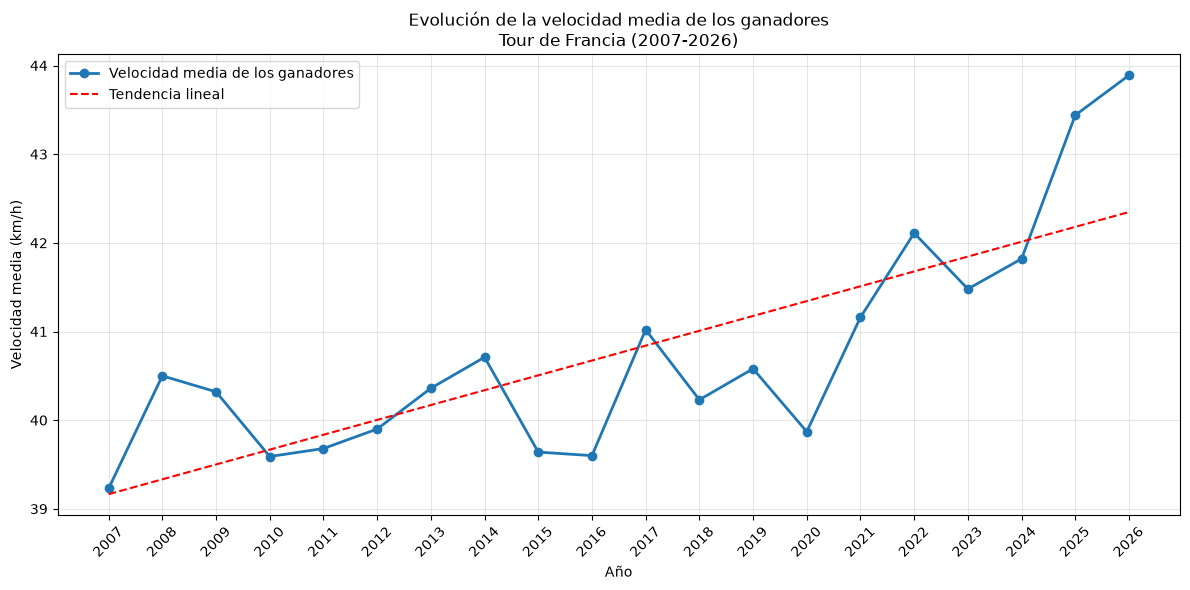

In [4]:

# ==========================================================
# H1: EVOLUCION DE LA VELOCIDAD DE LOS GANADORES
# ==========================================================

plt.figure(figsize=(12, 6))

# Datos observados
plt.plot(
    ganadores["Year"],
    ganadores["Speed_kmh"],
    marker="o",
    linewidth=2,
    label="Velocidad media de los ganadores"
)

# Tendencia lineal
x = ganadores["Year"]
y = ganadores["Speed_kmh"]

pendiente, intercepto = np.polyfit(x, y, 1)

plt.plot(
    x,
    pendiente * x + intercepto,
    linestyle="--",
    color="red",
    label="Tendencia lineal"
)

plt.title(
    "Evolución de la velocidad media de los ganadores\n"
    "Tour de Francia (2007-2026)"
)

plt.xlabel("Año")
plt.ylabel("Velocidad media (km/h)")

plt.xticks(ganadores["Year"], rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Planteamiento del contraste
### H1. Evolución de la velocidad media de los ganadores (2007-2026).
- Hipótesis nula (H₀): La velocidad media de los ganadores no presenta una tendencia creciente estadísticamente significativa (\(\beta_1 \leq 0\)).
- Hipótesis alternativa (Hₐ): La velocidad media de los ganadores presenta una tendencia creciente estadísticamente significativa (\(\beta_1 > 0\)).
Nivel de significación:
\[
\alpha=0.05
\]

### 2. Método estadístico
Utilizaremos una regresión lineal:
\[
Velocidad_i=\beta_0+\beta_1 Año_i+\varepsilon_i
\]

Donde:
- \(\beta_0\): velocidad estimada de referencia.
- \(\beta_1\): cambio promedio de velocidad por año.
- \(\varepsilon_i\): término de error.

In [5]:

# ==========================================================
# H1: CONTRASTE DE HIPOTESIS
# REGRESION LINEAL CON ERRORES HAC
# ==========================================================

# Variable temporal centrada
datos_h1 = ganadores.copy()
datos_h1["Year_c"] = (
    datos_h1["Year"] - datos_h1["Year"].mean()
)

# Modelo de regresion
X = sm.add_constant(datos_h1["Year_c"])
y = datos_h1["Speed_kmh"]

modelo_h1 = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 1}
)

# Resultados
beta = modelo_h1.params["Year_c"]
p_bilateral = modelo_h1.pvalues["Year_c"]
p_unilateral = (
    p_bilateral / 2 if beta > 0
    else 1 - p_bilateral / 2
)

ic = modelo_h1.conf_int().loc["Year_c"]

print("========== CONTRASTE H1 ==========")
print(modelo_h1.summary())

print("\n========== RESULTADOS ==========")
print(f"Coeficiente anual: {beta:.4f} km/h")
print(f"Valor p unilateral: {p_unilateral:.6f}")
print(f"IC 95%: [{ic.iloc[0]:.4f}, {ic.iloc[1]:.4f}]")
print(f"R²: {modelo_h1.rsquared:.4f}")

if beta > 0 and p_unilateral < 0.05:
    print("\nDECISION: EVIDENCIA A FAVOR DE H1")
else:
    print("\nDECISION: NO HAY EVIDENCIA SUFICIENTE PARA H1")


========== CONTRASTE H1 ==========
                            OLS Regression Results                            
Dep. Variable:              Speed_kmh   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     16.90
Date:               ju., 12 nov. 2026   Prob (F-statistic):           0.000655
Time:                        03:22:08   Log-Likelihood:                -23.068
No. Observations:                  20   AIC:                             50.14
Df Residuals:                      18   BIC:                             52.13
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         40.

### Conclusión de H1

Los resultados de la regresión lineal muestran una tendencia creciente estadísticamente significativa en la velocidad media de los ganadores del Tour de Francia durante el periodo 2007-2026. El coeficiente estimado fue de 0,1675 km/h por año, con un valor p unilateral de 0,000020, inferior al nivel de significación establecido (α = 0,05). Asimismo, el modelo presentó un coeficiente de determinación (R²) de 0,6134, lo que indica que el 61,34 % de la variabilidad de la velocidad se explica mediante la tendencia temporal considerada. Por tanto, se rechaza la hipótesis nula y se encuentra evidencia estadística a favor de la hipótesis alternativa, concluyendo que la velocidad media de los ganadores presentó una tendencia creciente durante el periodo analizado.


## H2. EVOLUCIÓN DE LAS DIFERENCIAS TEMPORALES

### Pregunta de investigación
¿Han cambiado significativamente las diferencias de tiempo entre los primeros clasificados del Tour de Francia durante el periodo 2007-2026?

### Hipótesis nula (H₀)
No existen diferencias estadísticamente significativas en las brechas temporales entre los periodos 2007-2016 y 2017-2026.

### Hipótesis alternativa (Hₐ)
Existen diferencias estadísticamente significativas en las brechas temporales entre ambos periodos.

### Objetivo
Analizar la evolución de las diferencias de tiempo entre los primeros clasificados y determinar si existen cambios entre las dos décadas estudiadas.


In [ ]:

# ==========================================================
# H2: PREPARACION DE DATOS
# ==========================================================

df_h2 = pd.read_csv("data/eda13_brechas_anuales.csv")

print("========== H2: DIFERENCIAS TEMPORALES ==========")

print("Registros:", len(df_h2))

print("\nColumnas disponibles:")
print(df_h2.columns.tolist())

print("\nDatos por edición:")
display(df_h2)

print("\nEstadísticas descriptivas:")
display(df_h2.describe())

print("\nValores faltantes:")
display(df_h2.isna().sum())


In [7]:

# ==========================================================
# H2: COMPARACION DE BRECHAS TEMPORALES POR DECADAS
# ==========================================================

import numpy as np
import pandas as pd

# Clasificar las ediciones
df_h2["Periodo"] = np.where(
    df_h2["Year"] <= 2016,
    "2007-2016",
    "2017-2026"
)

# Variables de estudio
variables_h2 = [
    "Brecha_segundo_segundos",
    "Brecha_decimo_segundos"
]

# Tabla resumen
resumen_h2 = df_h2.groupby("Periodo")[variables_h2].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

print("========== COMPARACION POR PERIODOS ==========")
display(resumen_h2)

# Diferencia entre las medias de ambos periodos
print("\n========== DIFERENCIA ENTRE DECADAS ==========")

for variable in variables_h2:
    medias = df_h2.groupby("Periodo")[variable].mean()
    diferencia = medias["2017-2026"] - medias["2007-2016"]

    print(f"\n{variable}")
    print(f"Diferencia de medias: {diferencia:.2f} segundos")


========== COMPARACION POR PERIODOS ==========


Brecha_segundo_segundos                                   \
                            count    mean  median     std min  max   
Periodo                                                              
2007-2016                      10 184.200 191.000 129.640  23  457   
2017-2026                      10 225.400 213.500 151.690  54  449   

          Brecha_decimo_segundos                                       
                           count     mean   median     std  min   max  
Periodo                                                                
2007-2016                     10  881.600  951.000 260.230  431  1275  
2017-2026                     10 1262.000 1303.000 570.630  452  2001


========== DIFERENCIA ENTRE DECADAS ==========

Brecha_segundo_segundos
Diferencia de medias: 41.20 segundos

Brecha_decimo_segundos
Diferencia de medias: 380.40 segundos


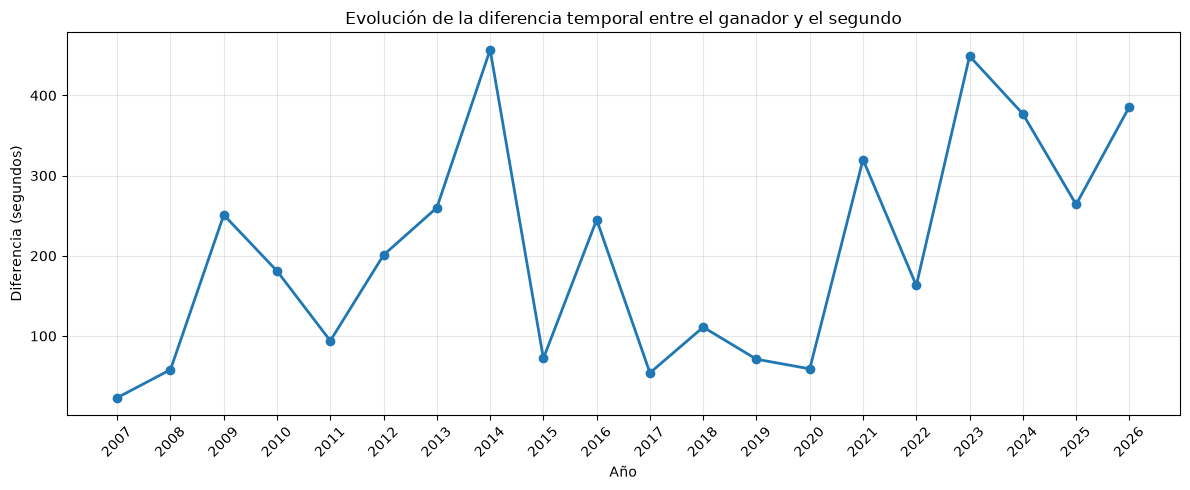

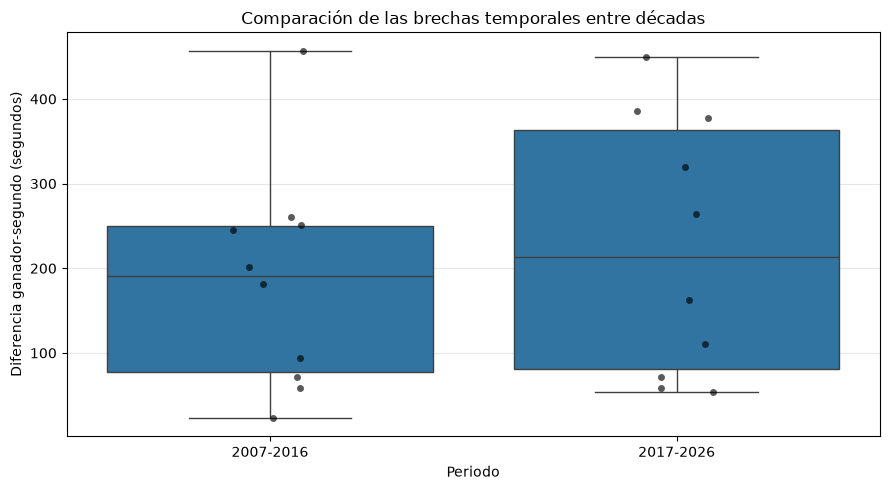

GRAFICOS H2 COMPLETADOS


In [8]:

# ==========================================================
# H2: GRAFICOS DE EVOLUCION Y COMPARACION
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Grafico 1: evolucion anual de la brecha ganador-segundo
plt.figure(figsize=(12, 5))

plt.plot(
    df_h2["Year"],
    df_h2["Brecha_segundo_segundos"],
    marker="o",
    linewidth=2
)

plt.title("Evolución de la diferencia temporal entre el ganador y el segundo")
plt.xlabel("Año")
plt.ylabel("Diferencia (segundos)")
plt.xticks(df_h2["Year"], rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Grafico 2: comparacion entre decadas
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_h2,
    x="Periodo",
    y="Brecha_segundo_segundos"
)

sns.stripplot(
    data=df_h2,
    x="Periodo",
    y="Brecha_segundo_segundos",
    color="black",
    alpha=0.65,
    jitter=True
)

plt.title("Comparación de las brechas temporales entre décadas")
plt.xlabel("Periodo")
plt.ylabel("Diferencia ganador-segundo (segundos)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("GRAFICOS H2 COMPLETADOS")


### Contraste estadístico

In [9]:

# ==========================================================
# H2: CONTRASTE ESTADISTICO
# ==========================================================

from scipy.stats import ttest_ind, mannwhitneyu

# Variable principal
grupo_1 = df_h2.loc[
    df_h2["Periodo"] == "2007-2016",
    "Brecha_segundo_segundos"
].dropna()

grupo_2 = df_h2.loc[
    df_h2["Periodo"] == "2017-2026",
    "Brecha_segundo_segundos"
].dropna()

# Prueba de Welch
resultado_welch = ttest_ind(
    grupo_1,
    grupo_2,
    equal_var=False
)

# Prueba Mann-Whitney
resultado_mw = mannwhitneyu(
    grupo_1,
    grupo_2,
    alternative="two-sided"
)

print("========== CONTRASTE H2 ==========")

print("\nPRUEBA DE WELCH")
print(f"Estadistico: {resultado_welch.statistic:.4f}")
print(f"Valor p: {resultado_welch.pvalue:.6f}")

print("\nPRUEBA MANN-WHITNEY")
print(f"Estadistico U: {resultado_mw.statistic:.4f}")
print(f"Valor p: {resultado_mw.pvalue:.6f}")

print("\n========== DECISION ==========")

if resultado_welch.pvalue < 0.05:
    print("Welch: diferencias estadisticamente significativas.")
else:
    print("Welch: no se detectan diferencias significativas.")

if resultado_mw.pvalue < 0.05:
    print("Mann-Whitney: diferencias en las distribuciones.")
else:
    print("Mann-Whitney: no se detectan diferencias significativas.")


========== CONTRASTE H2 ==========

PRUEBA DE WELCH
Estadistico: -0.6529
Valor p: 0.522255

PRUEBA MANN-WHITNEY
Estadistico U: 42.0000
Valor p: 0.570750

========== DECISION ==========
Welch: no se detectan diferencias significativas.
Mann-Whitney: no se detectan diferencias significativas.


### Conclusión de H2

Los resultados del análisis comparativo de las diferencias temporales entre los primeros clasificados del Tour de Francia durante los periodos 2007-2016 y 2017-2026 no evidenciaron cambios estadísticamente significativos. La prueba t de Welch obtuvo un valor p de 0,522255, mientras que la prueba U de Mann-Whitney presentó un valor p de 0,570750, ambos superiores al nivel de significación establecido (α = 0,05). En consecuencia, no se rechaza la hipótesis nula y no se encuentra evidencia estadística suficiente para afirmar que las brechas temporales hayan experimentado cambios significativos entre ambas décadas. Aunque se observan variaciones importantes entre determinadas ediciones, estas no permiten establecer una diferencia estadísticamente significativa entre los dos periodos analizados.

## H3. Concentración de los equipos en las posiciones del Top 10 (2007-2026)


### Pregunta de investigación
¿Existe una concentración de las posiciones del Top 10 del Tour de Francia en determinados equipos durante el periodo 2007-2026?

### Hipótesis nula (H₀)
No existe evidencia estadística de una concentración de las posiciones del Top 10 en determinados equipos.

### Hipótesis alternativa (Hₐ)
Existe evidencia estadística de una concentración de las posiciones del Top 10 en determinados equipos.

### Objetivo
Analizar la distribución de las posiciones del Top 10 entre los equipos participantes e identificar el grado de concentración competitiva durante las veinte ediciones estudiadas.


In [12]:

# ==========================================================
# H3: CONCENTRACION DE LOS EQUIPOS EN EL TOP 10
# ==========================================================

# Recuperar resumen de equipos del EDA 12
equipos_h3 = datos_h3["eda12_resumen_equipos"].copy()

# Ordenar por posiciones acumuladas
equipos_h3 = equipos_h3.sort_values(
    "Posiciones_Top10",
    ascending=False
).reset_index(drop=True)

# Calcular participacion porcentual
total_posiciones = equipos_h3["Posiciones_Top10"].sum()

equipos_h3["Participacion_pct"] = (
    equipos_h3["Posiciones_Top10"] /
    total_posiciones * 100
)

equipos_h3["Participacion_acumulada"] = (
    equipos_h3["Participacion_pct"].cumsum()
)

# Indicadores de concentracion
top3 = equipos_h3.head(3)["Participacion_pct"].sum()
top5 = equipos_h3.head(5)["Participacion_pct"].sum()
top10 = equipos_h3.head(10)["Participacion_pct"].sum()

# Indice Herfindahl-Hirschman (HHI)
participaciones = (
    equipos_h3["Posiciones_Top10"] / total_posiciones
)

hhi = (participaciones ** 2).sum()

print("========== H3: CONCENTRACION ==========")
print("Equipos analizados:", len(equipos_h3))
print("Posiciones contabilizadas:", total_posiciones)

print(f"\nConcentracion Top 3: {top3:.2f}%")
print(f"Concentracion Top 5: {top5:.2f}%")
print(f"Concentracion Top 10: {top10:.2f}%")
print(f"Indice HHI: {hhi:.4f}")

print("\n========== DIEZ EQUIPOS PRINCIPALES ==========")

display(
    equipos_h3[
        ["Team", "Posiciones_Top10",
         "Participacion_pct", "Participacion_acumulada"]
    ].head(10).round(2)
)


========== H3: CONCENTRACION ==========
Equipos analizados: 94
Posiciones contabilizadas: 198

Concentracion Top 3: 15.66%
Concentracion Top 5: 21.72%
Concentracion Top 10: 33.33%
Indice HHI: 0.0199

========== DIEZ EQUIPOS PRINCIPALES ==========


,Team,Posiciones_Top10,Participacion_pct,Participacion_acumulada
0,MOVISTAR TEAM,14,7.070,7.070
1,UAE TEAM EMIRATES,10,5.050,12.120
2,AG2R LA MONDIALE,7,3.540,15.660
3,TEAM SKY,6,3.030,18.690
4,ASTANA PRO TEAM,6,3.030,21.720
5,BMC RACING TEAM,5,2.530,24.240
6,EUSKALTEL - EUSKADI,5,2.530,26.770
7,INEOS GRENADIERS,5,2.530,29.290
8,BAHRAIN VICTORIOUS,4,2.020,31.310
9,BORA - HANSGROHE,4,2.020,33.330


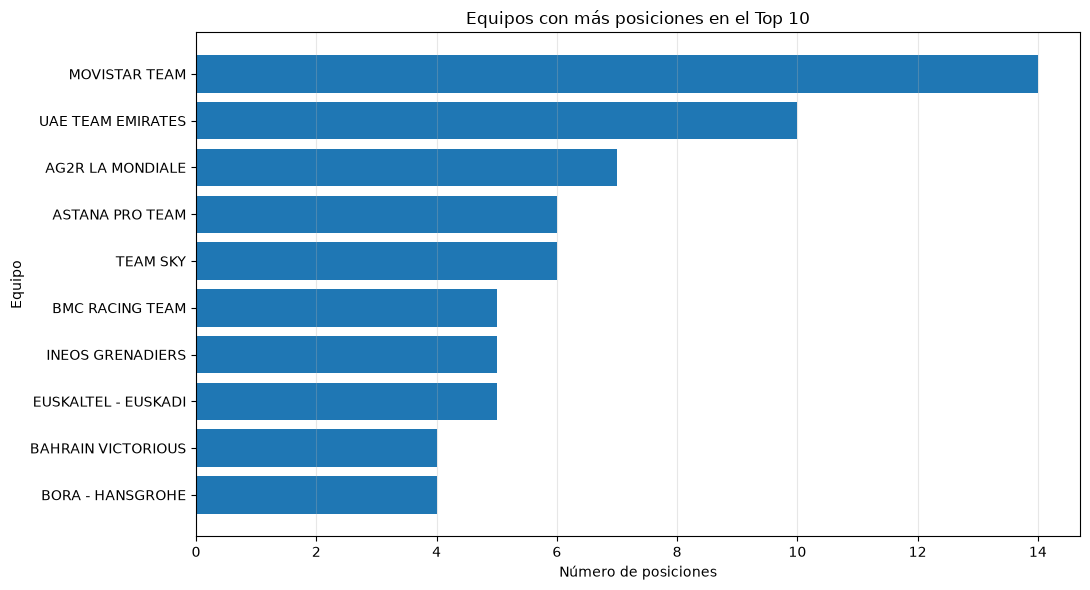

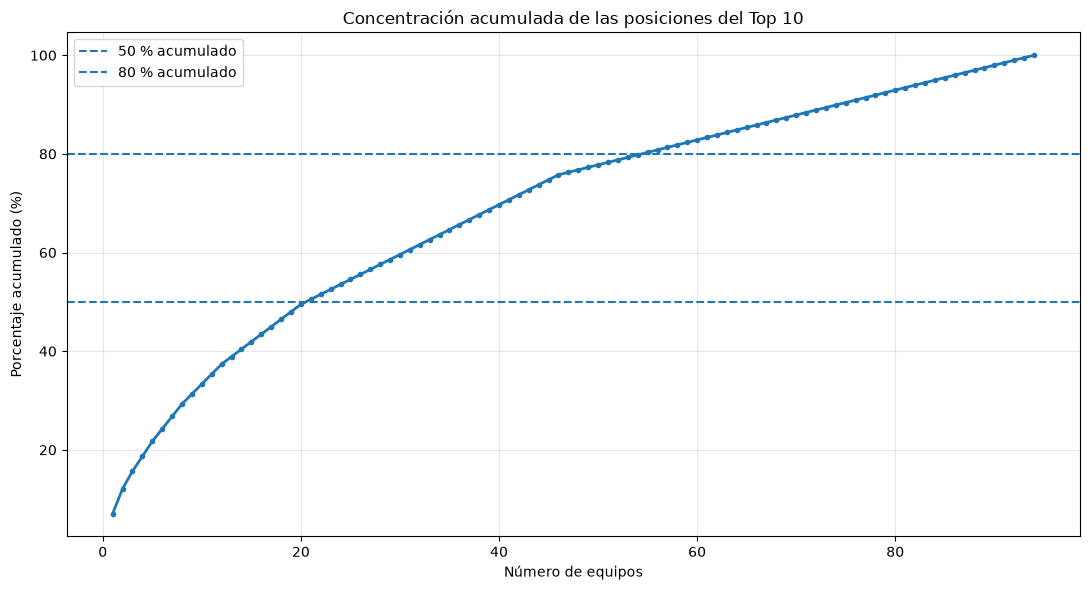

GRAFICOS H3 COMPLETADOS


In [13]:

# ==========================================================
# H3: VISUALIZACION DE LA CONCENTRACION
# ==========================================================

import matplotlib.pyplot as plt

# Grafico 1: equipos con mas posiciones Top 10
top_equipos = equipos_h3.head(10).sort_values(
    "Posiciones_Top10"
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_equipos["Team"],
    top_equipos["Posiciones_Top10"]
)

plt.title("Equipos con más posiciones en el Top 10")
plt.xlabel("Número de posiciones")
plt.ylabel("Equipo")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# Grafico 2: concentracion acumulada
plt.figure(figsize=(11, 6))

plt.plot(
    range(1, len(equipos_h3) + 1),
    equipos_h3["Participacion_acumulada"],
    marker=".",
    linewidth=2
)

plt.axhline(
    50,
    linestyle="--",
    label="50 % acumulado"
)

plt.axhline(
    80,
    linestyle="--",
    label="80 % acumulado"
)

plt.title("Concentración acumulada de las posiciones del Top 10")
plt.xlabel("Número de equipos")
plt.ylabel("Porcentaje acumulado (%)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("GRAFICOS H3 COMPLETADOS")


### Contraste descriptivo

In [14]:

# ==========================================================
# H3: CONTRASTE DESCRIPTIVO DE CONCENTRACION
# ==========================================================

total_equipos = len(equipos_h3)
total_posiciones = equipos_h3["Posiciones_Top10"].sum()

# Concentracion observada
hhi = (
    (equipos_h3["Posiciones_Top10"] / total_posiciones) ** 2
).sum()

# Referencia teorica de distribucion uniforme
hhi_uniforme = 1 / total_equipos

# Numero efectivo de equipos
equipos_efectivos = 1 / hhi

# Concentracion de los principales equipos
top3 = equipos_h3.head(3)["Participacion_pct"].sum()
top5 = equipos_h3.head(5)["Participacion_pct"].sum()
top10 = equipos_h3.head(10)["Participacion_pct"].sum()

print("========== CONTRASTE H3 ==========")

print(f"Equipos identificados: {total_equipos}")
print(f"Posiciones contabilizadas: {total_posiciones}")

print(f"\nHHI observado: {hhi:.4f}")
print(f"HHI de referencia uniforme: {hhi_uniforme:.4f}")
print(f"Numero efectivo de equipos: {equipos_efectivos:.2f}")

print(f"\nConcentracion Top 3: {top3:.2f}%")
print(f"Concentracion Top 5: {top5:.2f}%")
print(f"Concentracion Top 10: {top10:.2f}%")

print("\n========== INTERPRETACION ==========")

print(
    "El HHI observado es superior a la referencia "
    "de distribucion uniforme."
)

print(
    "Los diez equipos principales acumulan "
    f"el {top10:.2f}% de las posiciones identificadas."
)

print(
    "Este resultado describe una concentracion "
    "desigual, pero no constituye una prueba de "
    "significacion estadistica."
)

print("\nCONTRASTE DESCRIPTIVO H3 COMPLETADO")


========== CONTRASTE H3 ==========
Equipos identificados: 94
Posiciones contabilizadas: 198

HHI observado: 0.0199
HHI de referencia uniforme: 0.0106
Numero efectivo de equipos: 50.26

Concentracion Top 3: 15.66%
Concentracion Top 5: 21.72%
Concentracion Top 10: 33.33%

========== INTERPRETACION ==========
El HHI observado es superior a la referencia de distribucion uniforme.
Los diez equipos principales acumulan el 33.33% de las posiciones identificadas.
Este resultado describe una concentracion desigual, pero no constituye una prueba de significacion estadistica.

CONTRASTE DESCRIPTIVO H3 COMPLETADO


### Conclusión de H3.

El análisis de las posiciones del Top 10 del Tour de Francia durante el periodo 2007-2026 permitió identificar una distribución desigual del rendimiento competitivo entre los equipos participantes. De las 198 posiciones contabilizadas, los tres equipos con mayor presencia concentraron el 15,66 %, mientras que los diez principales acumularon el 33,33 %. Asimismo, el índice Herfindahl-Hirschman (HHI) alcanzó un valor de 0,0199, reflejando el grado de concentración observado en la distribución de las posiciones. Estos resultados muestran que determinados equipos presentan una mayor presencia competitiva, aunque las posiciones también se distribuyen entre numerosos equipos. Por tratarse de un análisis descriptivo, no se establece significación estadística ni se afirma que las diferencias observadas sean producto de una concentración estadísticamente significativa.


## H4. PERSISTENCIA DEL RENDIMIENTO COMPETITIVO INDIVIDUAL

### Pregunta de investigación
¿Los ciclistas que han conseguido entrar en el Top 10 del Tour de Francia tienen mayor probabilidad de repetir ese resultado en su siguiente participación?

### Hipótesis nula (H₀)
No existe asociación entre haber conseguido una posición en el Top 10 en una participación anterior y volver a conseguirla en la siguiente participación.

### Hipótesis alternativa (Hₐ)
Existe una asociación positiva entre haber conseguido una posición en el Top 10 en una participación anterior y volver a conseguirla en la siguiente participación.

### Objetivo
Analizar la persistencia del rendimiento competitivo individual mediante la comparación de las posiciones obtenidas por los ciclistas en participaciones consecutivas dentro de su historial registrado.


In [16]:

# ==========================================================
# H4: PREPARACION Y VALIDACION DE DATOS
# ==========================================================

df_h4 = pd.read_csv("data/eda14_transiciones.csv")

print("========== PREPARACION H4 ==========")

print("Transiciones:", len(df_h4))
print("Ciclistas:", df_h4["Rider_ID"].nunique())
print("Ediciones:", df_h4["Year"].nunique())

print("\nValores faltantes:")
display(df_h4.isna().sum())

print("\nPrimeros registros:")
display(df_h4.head(10))

print("\nEstadisticas descriptivas:")
display(df_h4.describe())


========== PREPARACION H4 ==========
Transiciones: 2079
Ciclistas: 645
Ediciones: 19

Valores faltantes:


Rider_ID                       0
Year                           0
Year_anterior                  0
Rank                           0
Top10                          0
Top10_anterior                 0
Anios_entre_participaciones    0
dtype: int64


Primeros registros:


,Rider_ID,Year,Year_anterior,Rank,Top10,Top10_anterior,Anios_entre_participaciones
0,ADAM JAMES HANSEN,2012,2008.000,82,0,0,4.000
1,ADAM JAMES HANSEN,2013,2012.000,72,0,0,1.000
2,ADAM JAMES HANSEN,2014,2013.000,64,0,0,1.000
3,ADAM JAMES HANSEN,2015,2014.000,114,0,0,1.000
4,ADAM JAMES HANSEN,2016,2015.000,100,0,0,1.000
5,ADAM JAMES HANSEN,2017,2016.000,113,0,0,1.000
6,ADAM YATES,2016,2015.000,4,1,0,1.000
7,ADAM YATES,2018,2016.000,29,0,1,2.000
8,ADAM YATES,2019,2018.000,29,0,0,1.000
9,ADAM YATES,2020,2019.000,9,1,0,1.000



Estadisticas descriptivas:


,Year,Year_anterior,Rank,Top10,Top10_anterior,Anios_entre_participaciones
count,2079.000,2079.000,2079.000,2079.000,2079.000,2079.000
mean,2017.117,2015.541,74.624,0.076,0.081,1.576
std,5.298,5.266,45.349,0.265,0.273,1.069
min,2008.000,2007.000,1.000,0.000,0.000,1.000
25%,2013.000,2011.000,35.000,0.000,0.000,1.000
50%,2017.000,2015.000,73.000,0.000,0.000,1.000
75%,2022.000,2020.000,111.000,0.000,0.000,2.000
max,2026.000,2025.000,173.000,1.000,1.000,9.000


In [17]:

# ==========================================================
# H4: TABLA DESCRIPTIVA DE TRANSICIONES
# ==========================================================

# Etiquetas de resultados
etiquetas_h4 = {
    0: "Fuera del Top 10",
    1: "Dentro del Top 10"
}

df_h4["Resultado_anterior"] = (
    df_h4["Top10_anterior"].map(etiquetas_h4)
)

df_h4["Resultado_actual"] = (
    df_h4["Top10"].map(etiquetas_h4)
)

orden_h4 = [
    "Fuera del Top 10",
    "Dentro del Top 10"
]

# Matriz de transiciones
matriz_h4 = pd.crosstab(
    df_h4["Resultado_anterior"],
    df_h4["Resultado_actual"]
).reindex(
    index=orden_h4,
    columns=orden_h4,
    fill_value=0
)

print("========== MATRIZ DE TRANSICIONES H4 ==========")
display(matriz_h4)

# Porcentajes por resultado anterior
porcentajes_h4 = (
    matriz_h4.div(matriz_h4.sum(axis=1), axis=0) * 100
)

print("\n========== PORCENTAJES DE TRANSICION ==========")
display(porcentajes_h4.round(2))

# Tabla de probabilidades
tabla_prob_h4 = df_h4.groupby(
    "Top10_anterior"
).agg(
    Participaciones=("Top10", "count"),
    Repiten_Top10=("Top10", "sum"),
    Probabilidad=("Top10", "mean")
)

tabla_prob_h4["Probabilidad"] *= 100

tabla_prob_h4.index = tabla_prob_h4.index.map(
    etiquetas_h4
)

print("\n========== PROBABILIDAD DE TOP 10 ==========")
display(tabla_prob_h4.round(2))

print("\nTABLA DESCRIPTIVA H4 COMPLETADA")


========== MATRIZ DE TRANSICIONES H4 ==========


Resultado_actual,Fuera del Top 10,Dentro del Top 10
Resultado_anterior,,
Fuera del Top 10,1829,82
Dentro del Top 10,92,76



========== PORCENTAJES DE TRANSICION ==========


Resultado_actual,Fuera del Top 10,Dentro del Top 10
Resultado_anterior,,
Fuera del Top 10,95.710,4.290
Dentro del Top 10,54.760,45.240



========== PROBABILIDAD DE TOP 10 ==========


,Participaciones,Repiten_Top10,Probabilidad
Top10_anterior,,,
Fuera del Top 10,1911,82,4.290
Dentro del Top 10,168,76,45.240



TABLA DESCRIPTIVA H4 COMPLETADA


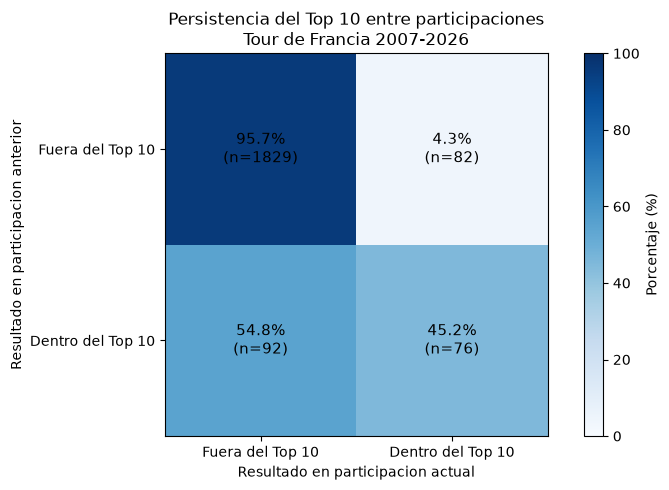

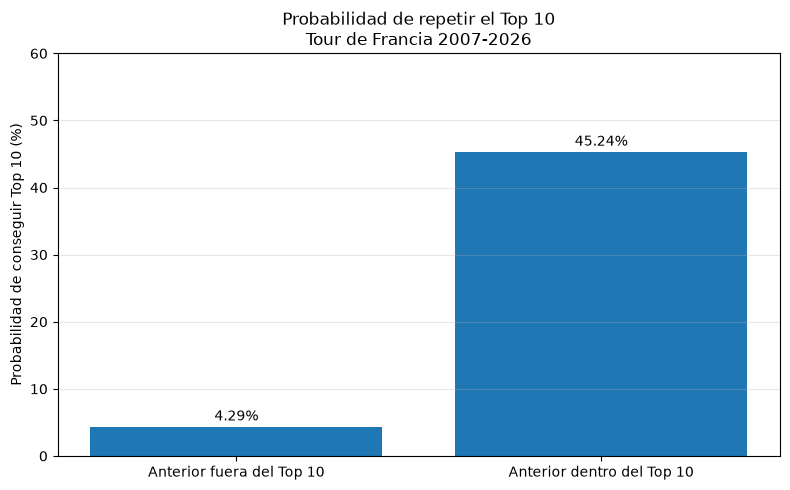

GRAFICOS H4 COMPLETADOS


In [18]:

# ==========================================================
# H4: GRAFICOS DEL RENDIMIENTO PERSISTENTE
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------------------------
# GRAFICO 1: MATRIZ DE TRANSICIONES
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(
    porcentajes_h4.values,
    cmap="Blues",
    vmin=0,
    vmax=100
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(orden_h4)
ax.set_yticklabels(orden_h4)

ax.set_xlabel("Resultado en participacion actual")
ax.set_ylabel("Resultado en participacion anterior")

ax.set_title(
    "Persistencia del Top 10 entre participaciones\n"
    "Tour de Francia 2007-2026"
)

for i in range(2):
    for j in range(2):
        valor = porcentajes_h4.iloc[i, j]
        cantidad = matriz_h4.iloc[i, j]

        ax.text(
            j, i,
            f"{valor:.1f}%\n(n={cantidad})",
            ha="center",
            va="center",
            color="black",
            fontsize=11
        )

fig.colorbar(im, ax=ax, label="Porcentaje (%)")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# GRAFICO 2: PROBABILIDAD DE REPETIR EL TOP 10
# ----------------------------------------------------------

probabilidades = [
    tabla_prob_h4.loc[
        "Fuera del Top 10", "Probabilidad"
    ],
    tabla_prob_h4.loc[
        "Dentro del Top 10", "Probabilidad"
    ]
]

nombres = [
    "Anterior fuera del Top 10",
    "Anterior dentro del Top 10"
]

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(nombres, probabilidades)

for barra, valor in zip(barras, probabilidades):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{valor:.2f}%",
        ha="center"
    )

ax.set_ylabel("Probabilidad de conseguir Top 10 (%)")
ax.set_title(
    "Probabilidad de repetir el Top 10\n"
    "Tour de Francia 2007-2026"
)

ax.set_ylim(0, 60)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("GRAFICOS H4 COMPLETADOS")


### Contraste estadistico

In [19]:

# ==========================================================
# H4: CONTRASTE INFERENCIAL
# REGRESION LOGISTICA GEE
# ==========================================================

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.cov_struct import Exchangeable

# Preparar variable temporal
df_h4["Year_c"] = (
    df_h4["Year"] - df_h4["Year"].mean()
) / 10

# Modelo GEE agrupado por ciclista
modelo_h4 = smf.gee(
    formula=(
        "Top10 ~ Top10_anterior + Year_c "
        "+ Anios_entre_participaciones"
    ),
    groups="Rider_ID",
    data=df_h4,
    family=sm.families.Binomial(),
    cov_struct=Exchangeable()
)

resultado_h4 = modelo_h4.fit()

print("========== CONTRASTE H4: MODELO GEE ==========")
print(resultado_h4.summary())

# ----------------------------------------------------------
# RESULTADOS DEL EFECTO PRINCIPAL
# ----------------------------------------------------------

coef = resultado_h4.params["Top10_anterior"]
p_valor = resultado_h4.pvalues["Top10_anterior"]

ic = resultado_h4.conf_int().loc["Top10_anterior"]

odds_ratio = np.exp(coef)
or_inferior = np.exp(ic.iloc[0])
or_superior = np.exp(ic.iloc[1])

print("\n========== EFECTO DE LA PARTICIPACION ANTERIOR ==========")

print(f"Coeficiente: {coef:.4f}")
print(f"Odds Ratio: {odds_ratio:.4f}")
print(f"Valor p: {p_valor:.6f}")

print(
    f"IC 95%: [{or_inferior:.4f}, "
    f"{or_superior:.4f}]"
)

# ----------------------------------------------------------
# DECISION
# ----------------------------------------------------------

print("\n========== DECISION H4 ==========")

if coef > 0 and p_valor < 0.05:
    print("EVIDENCIA A FAVOR DE H4")
    print("Existe una asociacion positiva significativa.")
else:
    print("NO SE CONFIRMA H4")
    print("No existe evidencia suficiente para aceptar H4.")

print("\nH4: CONTRASTE COMPLETADO")


========== CONTRASTE H4: MODELO GEE ==========
                               GEE Regression Results                              
Dep. Variable:                       Top10   No. Observations:                 2079
Model:                                 GEE   No. clusters:                      645
Method:                        Generalized   Min. cluster size:                   1
                      Estimating Equations   Max. cluster size:                  12
Family:                           Binomial   Mean cluster size:                 3.2
Dependence structure:         Exchangeable   Num. iterations:                    16
Date:                    ju., 12 nov. 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         03:52:26
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Inter

### Conclusión de H4. Persistencia del rendimiento competitivo individual

El análisis exploratorio mostró que los ciclistas que habían conseguido una posición dentro del Top 10 presentaban una mayor probabilidad descriptiva de repetir este resultado en su siguiente participación, alcanzando un 45,24 %, frente al 4,29 % de aquellos que anteriormente habían quedado fuera de los diez primeros puestos. Sin embargo, al desarrollar el análisis inferencial mediante un modelo de regresión logística GEE, que considera las participaciones repetidas de cada ciclista y controla el año y el intervalo entre participaciones, se obtuvo un Odds Ratio de 2,1953, con un valor p de 0,0775 e intervalo de confianza del 95 % de [0,9171; 5,2551]. Debido a que el valor p supera el nivel de significación del 5 % y el intervalo de confianza incluye la unidad, no se encontró evidencia estadística suficiente para confirmar una asociación positiva significativa. Por consiguiente, no se rechaza la hipótesis nula. Aunque los resultados descriptivos sugieren una posible persistencia del rendimiento competitivo individual, esta no pudo confirmarse estadísticamente mediante el modelo aplicado.

## GRAFICO RESUMEN GENERAL DE HIPOTESIS

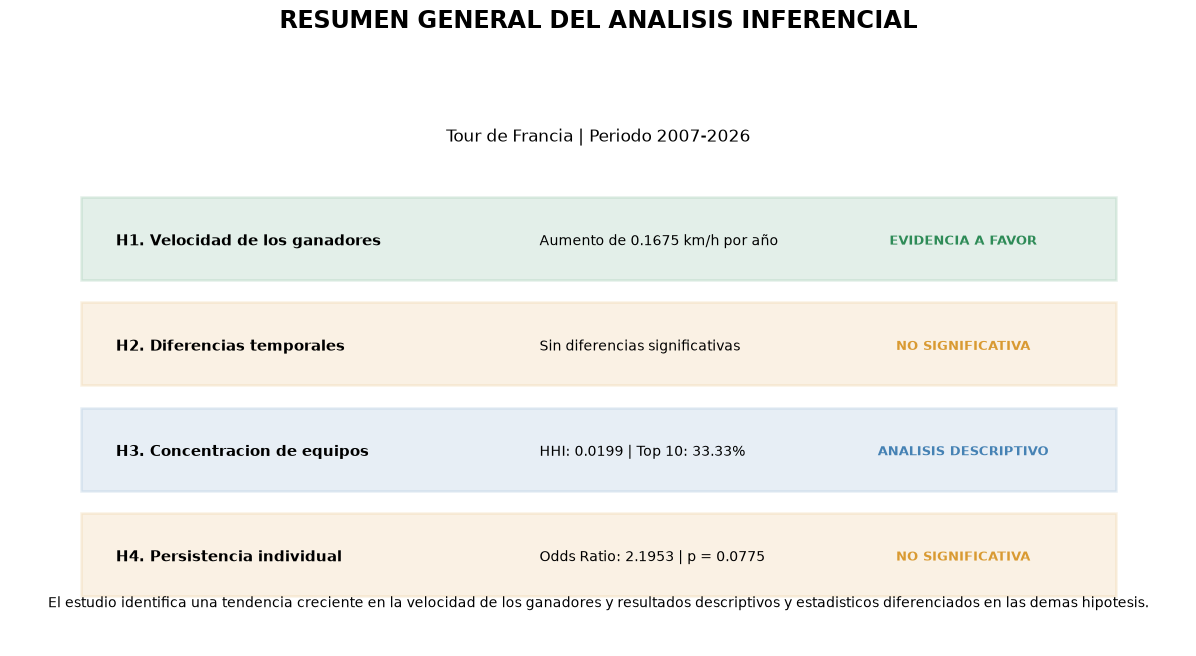

GRAFICO GENERAL DE HIPOTESIS COMPLETADO


In [22]:

# ==========================================================
# GRAFICO RESUMEN GENERAL DE HIPOTESIS
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import matplotlib.pyplot as plt
from textwrap import fill

# Informacion para el grafico
hipotesis = [
    "H1. Velocidad de los ganadores",
    "H2. Diferencias temporales",
    "H3. Concentracion de equipos",
    "H4. Persistencia individual"
]

resultados = [
    "Aumento de 0.1675 km/h por año",
    "Sin diferencias significativas",
    "HHI: 0.0199 | Top 10: 33.33%",
    "Odds Ratio: 2.1953 | p = 0.0775"
]

decisiones = [
    "EVIDENCIA A FAVOR",
    "NO SIGNIFICATIVA",
    "ANALISIS DESCRIPTIVO",
    "NO SIGNIFICATIVA"
]

colores = [
    "#2E8B57",
    "#D99A32",
    "#4682B4",
    "#D99A32"
]

# Crear figura
fig, ax = plt.subplots(figsize=(13, 7))

ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

fig.suptitle(
    "RESUMEN GENERAL DEL ANALISIS INFERENCIAL",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

ax.text(
    5, 4.55,
    "Tour de Francia | Periodo 2007-2026",
    ha="center",
    fontsize=12
)

# Dibujar cuatro bloques
for i in range(4):

    y = 3.65 - i * 0.95

    ax.add_patch(
        plt.Rectangle(
            (0.6, y - 0.35),
            8.8, 0.75,
            facecolor=colores[i],
            alpha=0.13,
            edgecolor=colores[i],
            linewidth=1.8
        )
    )

    ax.text(
        0.9, y,
        hipotesis[i],
        fontsize=11,
        fontweight="bold",
        va="center"
    )

    ax.text(
        4.5, y,
        resultados[i],
        fontsize=10,
        va="center"
    )

    ax.text(
        8.1, y,
        decisiones[i],
        fontsize=9,
        fontweight="bold",
        color=colores[i],
        ha="center",
        va="center"
    )

ax.text(
    5, 0.35,
    "El estudio identifica una tendencia creciente en la velocidad "
    "de los ganadores y resultados descriptivos y estadisticos "
    "diferenciados en las demas hipotesis.",
    ha="center",
    fontsize=10,
    wrap=True
)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])

plt.savefig(
    "data/resumen_grafico_hipotesis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("GRAFICO GENERAL DE HIPOTESIS COMPLETADO")



## CONCLUSIONES GENERALES DE LA INVESTIGACIÓN

### Evolución del rendimiento individual y colectivo en el Tour de Francia (2007-2026)

El análisis de la evolución del rendimiento individual y colectivo en el Tour de Francia durante el periodo 2007-2026 permitió identificar diferentes comportamientos en la competitividad de los ciclistas y equipos participantes.

En primer lugar, se encontró una tendencia creciente estadísticamente significativa en la velocidad media de los ganadores. La regresión lineal estimó un incremento de 0,1675 km/h por año, lo que evidencia una evolución positiva de este indicador durante las veinte ediciones analizadas.

En segundo lugar, la comparación de las diferencias temporales entre el ganador y el segundo clasificado, considerando los periodos 2007-2016 y 2017-2026, no mostró diferencias estadísticamente significativas. Esto indica que, con los datos analizados, no existe evidencia suficiente para afirmar que las brechas temporales hayan cambiado entre ambas décadas.

En tercer lugar, el análisis de la distribución de las posiciones del Top 10 permitió identificar diferencias en la presencia competitiva de los equipos. Los diez equipos con mayor número de posiciones acumularon el 33,33 % de las posiciones contabilizadas, lo que evidencia una distribución desigual del rendimiento colectivo entre los equipos participantes.

Finalmente, el análisis de la persistencia del rendimiento individual mostró que los ciclistas que anteriormente habían conseguido entrar en el Top 10 presentaban una mayor probabilidad descriptiva de repetir este resultado. Sin embargo, el modelo de regresión logística GEE no encontró evidencia estadística suficiente para confirmar una asociación significativa al nivel del 5 %.

En conjunto, los resultados muestran que la evolución del rendimiento en el Tour de Francia presenta comportamientos diferentes según el indicador analizado. Mientras que la velocidad media de los ganadores evidencia una tendencia creciente, las diferencias temporales, la concentración de equipos y la persistencia individual presentan resultados que requieren interpretaciones diferenciadas. Por tanto, la evolución competitiva del Tour de Francia entre 2007 y 2026 no puede explicarse mediante un único indicador, sino a través de la combinación de factores individuales y colectivos.



## DISCUSIÓN DE RESULTADOS

## 1. Evolución de la velocidad media de los ganadores

Los resultados muestran una tendencia creciente estadísticamente significativa en la velocidad media de los ganadores del Tour de Francia durante el periodo 2007-2026. El incremento estimado de 0,1675 km/h por año evidencia una evolución positiva de este indicador. Este comportamiento permite identificar cambios en el rendimiento competitivo de los ganadores a lo largo del periodo estudiado. Sin embargo, los resultados no permiten atribuir esta tendencia a una causa específica, por lo que sería necesario incorporar otras variables para explicar los factores asociados a dicha evolución.

## 2. Evolución de las diferencias temporales

La comparación entre los periodos 2007-2016 y 2017-2026 no permitió identificar diferencias estadísticamente significativas en las brechas temporales entre los primeros clasificados. Aunque los gráficos muestran variaciones entre determinadas ediciones, estas no fueron suficientes para establecer un cambio significativo entre ambas décadas. Este resultado indica que el incremento de la velocidad media de los ganadores no implica necesariamente una modificación estadísticamente demostrable de las diferencias temporales entre los principales competidores.

## 3. Concentración del rendimiento colectivo de los equipos

El análisis descriptivo permitió identificar diferencias en la presencia de los equipos dentro del Top 10. Los diez equipos con mayor representación acumularon el 33,33 % de las posiciones contabilizadas, mientras que los tres primeros concentraron el 15,66 %. Estos resultados muestran que algunos equipos han conseguido una mayor presencia competitiva durante el periodo estudiado. No obstante, la participación de 94 equipos también evidencia que las posiciones destacadas se distribuyen entre numerosas organizaciones. Al tratarse de un análisis descriptivo, estos resultados no permiten establecer una significación estadística de la concentración observada.

## 4. Persistencia del rendimiento competitivo individual

Los resultados descriptivos mostraron que los ciclistas que habían conseguido entrar previamente en el Top 10 presentaban una probabilidad del 45,24 % de repetir ese resultado, frente al 4,29 % de quienes anteriormente habían quedado fuera. Sin embargo, el modelo GEE, que consideró las participaciones repetidas de los ciclistas, no encontró una asociación estadísticamente significativa al nivel del 5 %. El Odds Ratio obtenido fue de 2,1953, con un valor p de 0,0775. Por tanto, aunque se observa una tendencia positiva en la persistencia del rendimiento, no existe evidencia estadística suficiente para confirmarla mediante el modelo aplicado.

## 5. Integración de los resultados

En conjunto, los resultados evidencian que la evolución del rendimiento individual y colectivo en el Tour de Francia presenta diferentes comportamientos según la dimensión analizada. La velocidad media de los ganadores mostró una tendencia creciente estadísticamente significativa, mientras que las diferencias temporales entre décadas no presentaron cambios significativos. Por su parte, el rendimiento colectivo mostró una distribución desigual entre equipos y el análisis individual sugirió una posible persistencia del éxito competitivo que no pudo confirmarse estadísticamente.

Estos hallazgos permiten comprender que la evolución competitiva del Tour de Francia es un fenómeno multidimensional, en el que los cambios en el rendimiento de los ganadores no necesariamente se corresponden con modificaciones en las diferencias temporales, la distribución del éxito entre equipos o la continuidad de los resultados individuales.


## Limitaciones del estudio

La presente investigación presenta algunas limitaciones que deben considerarse al interpretar sus resultados. En primer lugar, el análisis se circunscribe al periodo 2007-2026, por lo que sus hallazgos no necesariamente representan el comportamiento histórico del Tour de Francia en otras épocas.

En segundo lugar, el estudio depende de la disponibilidad y consistencia de los registros históricos. En el análisis de concentración de equipos se identificaron dos registros faltantes de los 200 previstos, lo que limita parcialmente la cobertura de los datos. Asimismo, los cambios de denominación y patrocinio de los equipos dificultan el seguimiento de su continuidad a lo largo del tiempo.

Por otra parte, la velocidad de los ganadores y la regularidad competitiva están condicionadas por factores externos, como las características del recorrido, el clima, las estrategias de carrera y los avances tecnológicos, variables que no fueron incorporadas directamente en el análisis.

Finalmente, debido al carácter observacional del estudio, los resultados permiten identificar tendencias y asociaciones, pero no establecer relaciones causales. Por tanto, las conclusiones deben interpretarse dentro del periodo, las variables y la información disponible.

## Recomendaciones y futuras líneas de investigación

A partir de los resultados obtenidos, se recomienda ampliar el periodo de estudio para analizar la evolución del rendimiento en el Tour de Francia desde una perspectiva histórica más extensa. Asimismo, sería conveniente incorporar variables relacionadas con las características de los recorridos, como la distancia, el desnivel acumulado y las condiciones meteorológicas, con el propósito de profundizar en los factores asociados al incremento de la velocidad media de los ganadores.

Por otra parte, se sugiere profundizar en el análisis de la concentración competitiva de los equipos y la persistencia individual de los ciclistas, utilizando indicadores adicionales que permitan comprender mejor la continuidad de los resultados a lo largo de las distintas ediciones. Finalmente, futuras investigaciones podrían aplicar modelos estadísticos que consideren la dependencia temporal de los datos y las participaciones repetidas de los corredores, con el fin de obtener una comprensión más amplia de la evolución del rendimiento individual y colectivo en el ciclismo profesional.